In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

with open("ID.txt") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, '')
)

json_data = response.json()

if response.status_code == 200:
    data = json_data['data']

    print('Data retrieved from frost.met.no!')

    rows = []

    for item in data:
        row = pd.DataFrame(item['observations'])
        row['referenceTime'] = item['referenceTime']
        row['sourceId'] = item['sourceId']
        rows.append(row)

    df = pd.concat(rows, ignore_index=True)

    # The original data contains multiple time offsets, we keep only one daily time offset
    df = df[df['timeOffset'] == 'PT0H'].copy()

    # Convert timestamps so they can be sorted and plotted as dates
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

    # Sort chronologically
    df = df.sort_values('referenceTime')

    # Define x and y values
    xpoints = df['referenceTime']
    ypoints = df['value']

    plt.plot(xpoints, ypoints, marker='.', markersize=2)

    plt.xlabel('Date')
    plt.ylabel('Mean air temperature (°C)')
    plt.title('Daily mean temperature at SN17850 - 2025')
    
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

    mean_temp = df['value'].mean()
    median_temp = df['value'].median()
    min_temp = df['value'].min()
    max_temp = df['value'].max()

    summary = pd.DataFrame({
        'Statistic': ['Mean', 'Median', 'Min', 'Max'],
        'Temperature (°C)': [mean_temp.round(2),
        median_temp.round(2),
        min_temp.round(2),
        max_temp.round(2)]
    })

    print(summary.to_string(index=False))

else:
    print(f'Error! Returned status code {response.status_code}')
    print(f"Message: {json_data['error']['message']}")
    print(f"Reason: {json_data['error']['reason']}")

ModuleNotFoundError: No module named 'requests'

Data retrieved from frost.met.no!
                     elementId  value  unit  \
0    mean(air_temperature P1D)   -5.2  degC   
2    mean(air_temperature P1D)  -11.5  degC   
4    mean(air_temperature P1D)   -8.9  degC   
6    mean(air_temperature P1D)  -15.5  degC   
8    mean(air_temperature P1D)  -12.5  degC   
..                         ...    ...   ...   
718  mean(air_temperature P1D)   -2.9  degC   
720  mean(air_temperature P1D)   -0.6  degC   
722  mean(air_temperature P1D)   -4.6  degC   
724  mean(air_temperature P1D)   -3.6  degC   
726  mean(air_temperature P1D)   -3.0  degC   

                                                 level timeOffset  \
0    {'levelType': 'height_above_ground', 'unit': '...       PT0H   
2    {'levelType': 'height_above_ground', 'unit': '...       PT0H   
4    {'levelType': 'height_above_ground', 'unit': '...       PT0H   
6    {'levelType': 'height_above_ground', 'unit': '...       PT0H   
8    {'levelType': 'height_above_ground', 'unit': '...  

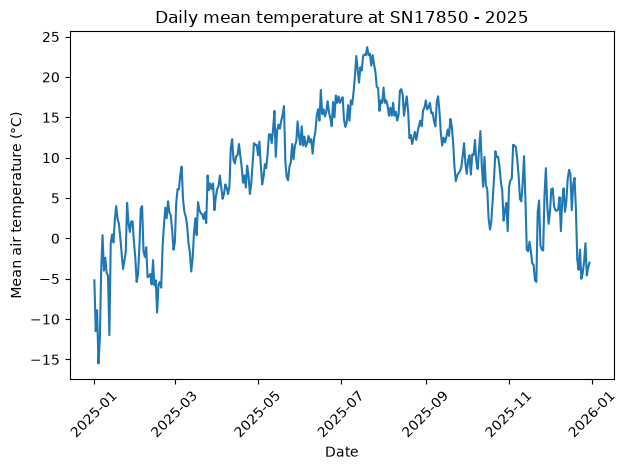

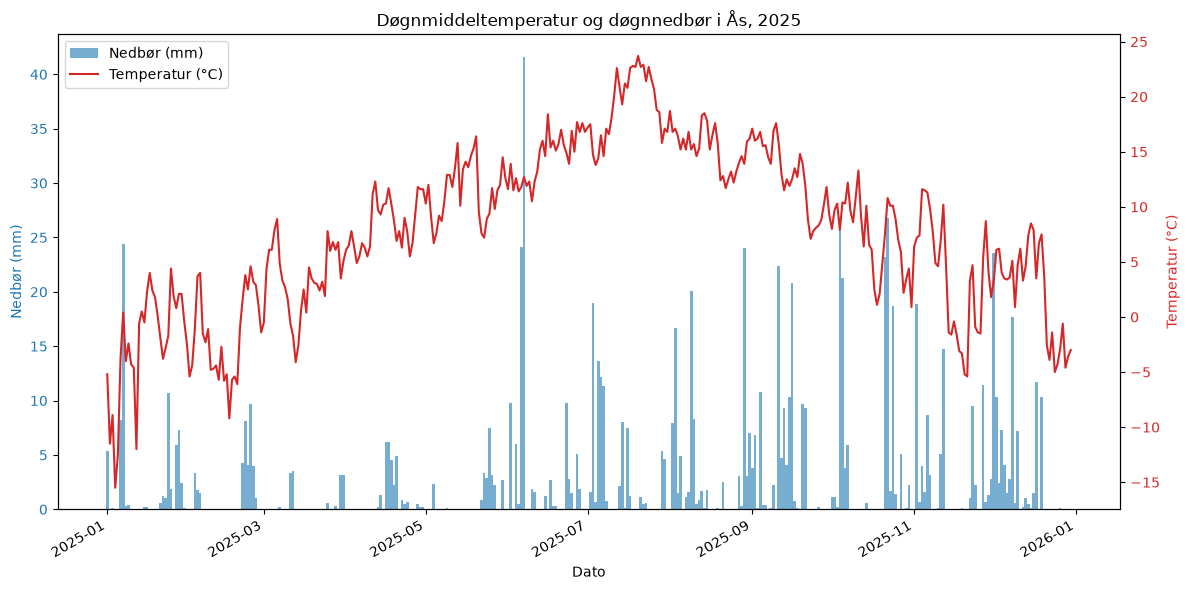

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

with open("ID.txt") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, '')
)

json_data = r.json()

if r.status_code == 200:
    data = json_data['data']

    print('Data retrieved from frost.met.no!')

    rows = []

    for item in data:
        row = pd.DataFrame(item['observations'])
        row['referenceTime'] = item['referenceTime']
        row['sourceId'] = item['sourceId']
        rows.append(row)

    df = pd.concat(rows, ignore_index=True)

    # Keep only one daily time offset
    df = df[df['timeOffset'] == 'PT0H'].copy()

    # Convert Frost timestamp to datetime
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

    # Sort chronologically
    df = df.sort_values('referenceTime')

    print(df)

    # Define x and y values
    xpoints = df['referenceTime']
    ypoints = df['value']

    # Plot
    plt.plot(xpoints, ypoints)

    plt.xlabel('Date')
    plt.ylabel('Mean air temperature (°C)')
    plt.title('Daily mean temperature at SN17850 - 2025')

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

else:
    print(f'Error! Returned status code {r.status_code}')
    print(f"Message: {json_data['error']['message']}")
    print(f"Reason: {json_data['error']['reason']}")


parameters_prec = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

response_prec = requests.get(
    endpoint,
    params=parameters_prec,
    auth=(client_id, '')
)

json_prec = response_prec.json()

if response_prec.status_code == 200:
    rows = []
    for item in json_prec['data']:
        obs = pd.DataFrame(item['observations'])
        obs['referenceTime'] = item['referenceTime']
        rows.append(obs)

    df_prec = pd.concat(rows, ignore_index=True)

    df_prec['referenceTime'] = pd.to_datetime(df_prec['referenceTime'])
    df_prec = df_prec.sort_values('referenceTime').drop_duplicates('referenceTime')

    fig, ax1 = plt.subplots(figsize=(12, 6))

    ax1.bar(df_prec['referenceTime'], df_prec['value'],
            color='tab:blue', alpha=0.6, width=1.0, label='Nedbør (mm)')
    ax1.set_xlabel('Dato')
    ax1.set_ylabel('Nedbør (mm)', color='tab:blue')
    ax1.tick_params(axis='y', labelcolor='tab:blue')

    ax2 = ax1.twinx()
    ax2.plot(df['referenceTime'], df['value'],
             color='tab:red', linewidth=1.5, label='Temperatur (°C)')
    ax2.set_ylabel('Temperatur (°C)', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper left')

    plt.title('Døgnmiddeltemperatur og døgnnedbør i Ås, 2025')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

else:
    print(f'Error! Returned status code {response_prec.status_code}')
    print(f"Message: {json_prec['error']['message']}")
    print(f"Reason: {json_prec['error']['reason']}")

    

In [18]:
""" task 4 """

import yaml 
import requests
import pandas as pd

with open("ID.txt") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'max(air_temperature P1D)', # endres fra mean til max, siden vi ønsker maks temperatur. 
    'referencetime': '2025-01-01/2026-01-01', # endres fra 2025-12-31 til 2026-01-01, for å inkludere hele året 2025. 
}

r = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, '')
)

json_data = r.json()

rows = []

for item in json_data['data']:
    obs = pd.DataFrame(item['observations'])
    obs['referenceTime'] = item['referenceTime'] #Datoen ligger utenfor observations, så vi legger den til som en kolonne. Ellers vet vi ikke hvilken dag verdien hører til.
    rows.append(obs)

df_max = pd.concat(rows, ignore_index=True)
df_max['referenceTime'] = pd.to_datetime(df_max['referenceTime']) # Konverterer referenceTime til datetime, slik at vi kan sortere og plotte det som datoer.
df_max = df_max.sort_values('referenceTime').drop_duplicates('referenceTime') # sorterer fra første til siste dag, og fjerner duplikater.

print(len(df_max))

df_max['hot'] = df_max['value'] >= 27

print(f"In the year 2025 there were: {df_max['hot'].sum()} hot days in Ås")

print(df_max[df_max['hot']][['referenceTime', 'value']])


heatwaves = []   # ferdige hetebølger
streak = []      # rekken vi er i akkurat nå

for date, hot in zip(df_max['referenceTime'], df_max['hot']):
    if hot:
        streak.append(date)
    else:
        if len(streak) >= 5:
            heatwaves.append(streak)
        streak = []

# rekken som evt. varer ut året
if len(streak) >= 5:
    heatwaves.append(streak)

print(f"In the year 2025 there were {len(heatwaves)} heatwave(s) in Ås")
for w in heatwaves:
    print(f"Heatwave from {w[0].date()} to {w[-1].date()} ({len(w)} days)")



365
In the year 2025 there were: 10 hot days in Ås
                referenceTime  value
382 2025-07-11 00:00:00+00:00   28.0
384 2025-07-12 00:00:00+00:00   28.1
392 2025-07-16 00:00:00+00:00   28.3
394 2025-07-17 00:00:00+00:00   29.5
397 2025-07-18 00:00:00+00:00   30.1
398 2025-07-19 00:00:00+00:00   29.9
400 2025-07-20 00:00:00+00:00   30.8
404 2025-07-22 00:00:00+00:00   28.4
409 2025-07-24 00:00:00+00:00   29.4
410 2025-07-25 00:00:00+00:00   27.6
In the year 2025 there were 1 heatwave(s) in Ås
Heatwave from 2025-07-16 to 2025-07-20 (5 days)


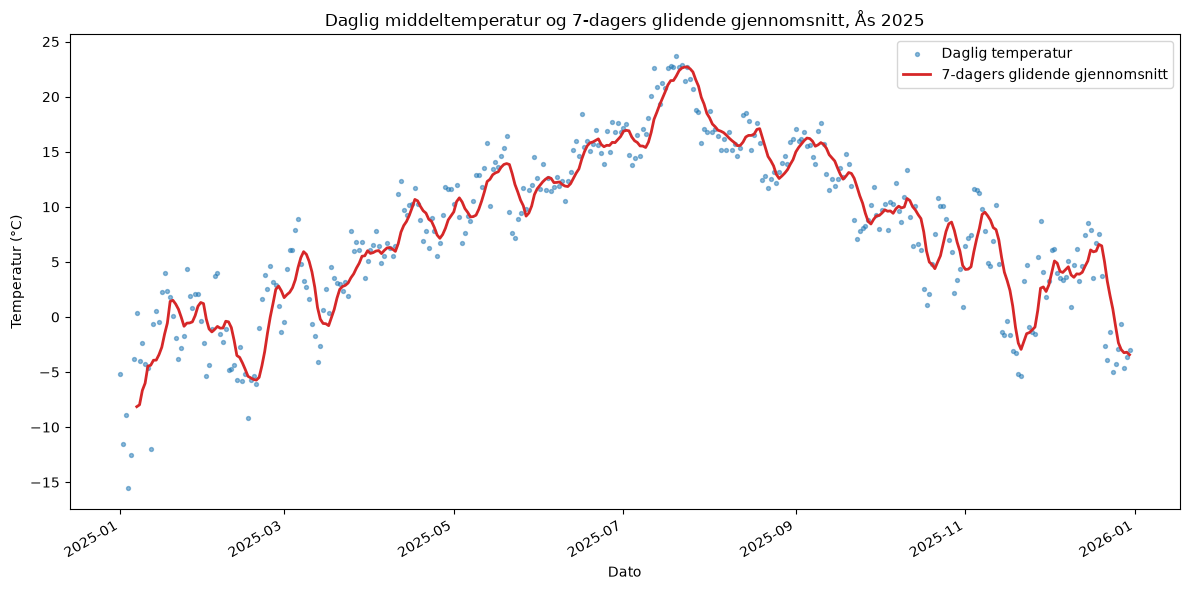

In [ ]:
""" task 5 """


def moving_average(values, window=7): # window=7 betyr at vi tar glidende gjennomsnitt over 7 dager.
    """Returnerer glidende gjennomsnitt av en kolonne/serie."""
    return values.rolling(window=window).mean() # rolling hjelper med å lage et glidende gjennomsnitt, og mean tar gjennomsnittet av de siste 7 verdiene.


fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(df['referenceTime'], df['value'], # scatter plot for å vise alle verdiene, med s=8 for å gjøre punktene litt større, og alpha=0.5 for å gjøre dem litt gjennomsiktige.
           s=8, color='tab:blue', alpha=0.5, label='Daglig temperatur')
ax.plot(df['referenceTime'], df['moving_avg'],
        color='tab:red', linewidth=2, label='7-dagers glidende gjennomsnitt') # plot for å vise glidende gjennomsnitt, med linewidth=2 for å gjøre linjen litt tykkere.

ax.set_xlabel('Dato')
ax.set_ylabel('Temperatur (°C)')
ax.set_title('Daglig middeltemperatur og 7-dagers glidende gjennomsnitt, Ås 2025')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()